# Setup 

In [39]:
import sys
import os
from importlib import reload
from collections import Counter
import re 
from operator import or_, is_not
from functools import reduce, partial
import pprint
import pandas as pd
import matplotlib.pyplot as plt
import bibtexparser
import json
sys.path.append(os.getcwd())
from sonicsocialgenre import loader


In [3]:
def cite_cmd(keys):
    if not isinstance(keys,list):
        keys = [keys]
    return f'\cite{{{", ".join(keys)}}}'

# Load Data 

In [6]:
reload(loader) # to absorb db shape changes without restarting env

# data from original survey
olddat = loader.load_survey_data(
    "data/original_survey.csv",skiprows=[0,2,3], map=loader.datamaps["old"]
)

# new data 
newdat = loader.load_survey_data(
    "data/new_survey.csv",skiprows=[0,2], map=loader.datamaps["new"]
)

# bibliography 
library = bibtexparser.parse_file('data/articles.bib')

# Validation

In [7]:
# Test that spreadsheet and bibliography line up 

bib_keys = library.entries_dict.keys()
csv_keys = newdat.index

# Any duplicate keys in either?
def duplicate_count(keys):
    from collections import Counter
    counts = Counter(keys)
    dups = [k for k, n in counts.items() if n > 1]
    return len(dups)
assert(duplicate_count(bib_keys) == 0)
assert(duplicate_count(csv_keys) == 0)

# Key sets match? 
try: 
    assert(len(set(bib_keys).symmetric_difference(set(csv_keys))) == 0)
    print('Bib and CSV match up!')
except AssertionError:
     print(set(bib_keys).symmetric_difference(set(csv_keys)))

Bib and CSV match up!


### Make a `\cite` command 

In [8]:
# cite all the library things 
print(cite_cmd(list(library.entries_dict.keys())))

\cite{AbbasiLayegh2013, Abesser2014, Adiyansjah2019, Afchar2022, Agarwal2013, Agera2015, Agrawal2020, Aguiar2018, Ahmad2014, Ahmed2016, Ajoodha2014, Ajoodha2015, Akalp2021, Al-Tamimi2020, Alexandridis2014, Ali2017, Allamy2021, AlMamun2019, Almeida2022, Anden2014, Andreas2013, Anglade2014, Antunes2014, Arenas-Garcia2013, Arjannikov2014, Arjannikov2015, Arjannikov2016, Armentano2017, Aryafar2014, Astefanoaei2020, Atahan2021, Athulya2021, Bahuleyan2018, Bajpai2018, Banitalebi-Dehkordi2014, Banitalebi-Dehkordi2018, Baniya2013, Baniya2013a, Baniya2014, Baniya2014a, Baniya2015a, Baniya2016, Bassiou2015, Bernabeu2013, Bhatia2021, Bhowmik2019, Bisharad2019, Bisharad2019a, Bodo2018, Bogdanov2016, Bogdanov2019, Bogdanov2019a, Boonmatham2013, Bruni2022, Brunner2018, Bu2022, Buchmuller2020, Budhrani2020, Bulos2014, Cai2021, Cai2022, Cai2022a, Campobello2020, CapoClar2014, Casana-Eslava2021, Castellon2021, Castillo2021, Ceylan2021, Chak2022, Chang2021, Chang2021a, Chapaneri2015, Chathuranga2013a, C

# Counts for Paper

## Publication Types

In [9]:

print(newdat.type.sum(axis=0))

print(cite_cmd(list(newdat[newdat.type.Review > 0].index)))
print(cite_cmd(list(newdat[newdat.type.Evaluation > 0].index)))
print(cite_cmd(list(newdat[newdat.type.Experimental > 0].index)))

Review            9.0
Evaluation       19.0
Experimental    546.0
dtype: float64
\cite{Kostek2013a, Sturm2013c, Nasridinov2014, Sturm2014d, Tzanetakis2014, Correa2016, Hoang2018, Narkhede2022, Ozseven2022}
\cite{Sturm2013c, Sturm2013e, Sturm2013g, Sturm2013h, Sturm2014c, Sturm2014d, Kereliuk2015, Kereliuk2015a, Schreiber2015, Sturm2015b, Porter2016, Rodriguez-Algarra2016, Sturm2016b, Defferrard2017, Hossain2018, Palmason2018, Rodriguez-Algarra2019, Nie2022, Sturm2015c}
\cite{deLeon2004, Flexer2005b, Hu2005, Peeters2005, Hansen2007, Hockman2008, Schuller2008, ForoughmandArabi2009, Itoyama2009, Schnitzer2012, AbbasiLayegh2013, Agarwal2013, Andreas2013, Arenas-Garcia2013, Baniya2013, Baniya2013a, Bernabeu2013, Boonmatham2013, Chathuranga2013a, Chen2013, Conklin2013, Coronel2013, Costa2013, Costa2013a, Dieleman2013, Doudpota2013, Foucard2013, Hamel2013, Haq2013, HaroBerois2013, Hartmann2013, Jao2013, Jensen2013, Koerich2013, Kostek2013a, Kotsifakos2013, Markov2013, Markov2013a, Martel2013,

## Datasets

In [10]:
# Top 5 datasets
print(newdat.datasets.sum(axis=0).sort_values(ascending=False).head(n=5))


GTZAN        254.0
ISMIR2004     50.0
FMA           37.0
MSD           32.0
Latin         24.0
dtype: float64


### Private datasets

In [12]:
# use private datasets 
print(f'{newdat.aggregates["Private data"].sum(axis=0)} papers use private data')
# use only private data 
only_private = len(newdat[(newdat.datasets.sum(axis=1) < 1) & (newdat.aggregates["Private data"] > 0)])
print(f'{only_private} papers use only private data')

180.0 papers use private data
147 papers use only private data


### Modalities

In [13]:
print(newdat[newdat.type.Experimental > 0].data_types.sum(axis=0))

audio_and_sym = newdat[(newdat.type.Experimental > 0) & (newdat.data_types["Music audio"] > 0) & (newdat.data_types["Music symb. data"] > 0)]
print(f'{len(audio_and_sym)} use both audio and symbolic')


Music audio                       483.0
Music symb. data                   40.0
other (lyrics, WWW, playlists)     67.0
Non-Western?                       60.0
dtype: float64
11 use both audio and symbolic


## Experimental Designs 

In [14]:
experiments = newdat[newdat.type.Experimental > 0]
print(experiments.doe.sum(axis=0).sort_values(ascending=False)) 

only_classify = experiments[(experiments.doe.Classify > 0) & (experiments.doe.sum(axis=1) < 2)]

print(f'{len(only_classify)} papers just use Classify')
print("Papers that use Compose:")
print(cite_cmd(list(experiments[experiments.doe["Compose"] > 0].index)))


Classify      515.0
Feature       144.0
Generalize    126.0
Cluster        51.0
Eyeball        35.0
Robust         15.0
Retrieve        8.0
Scale           8.0
Rules           6.0
Compose         5.0
dtype: float64
266 papers just use Classify
Papers that use Compose:
\cite{Itoyama2009, Sturm2015b, Goienetxea2018, Tokui2020, Tang2022}


## Figures of Merit

In [17]:
fom_table = experiments.fom.sum(axis=0).sort_values(ascending = False)
print(fom_table)
print(f'\n{fom_table["Confusion matrix"] - fom_table["conf. Discussion"]} papers conf table without discussion')
print("\nThese papers do confusion instances")
print(cite_cmd(list(experiments[experiments.fom['confusion instances'] > 0].index)))


Accuracy                   449.0
Confusion matrix           194.0
conf. Discussion           116.0
Precision                  106.0
Recall                     102.0
F1                          64.0
ROC                         39.0
confusion instances          9.0
mean log loss                3.0
balanced relative error      1.0
dtype: float64

78.0 papers conf table without discussion

These papers do confusion instances
\cite{Sturm2013c, Sturm2013g, Sturm2014, Kereliuk2015, Kereliuk2015a, Sturm2015a, Palmason2018, Campobello2020, Hsu2021}


# Publications by Year

[<BarContainer object of 29 artists>]
Rectangle(xy=(1995, 0), width=0.5, height=1, angle=0)
Rectangle(xy=(1996, 0), width=0.5, height=0, angle=0)
Rectangle(xy=(1997, 0), width=0.5, height=1, angle=0)
Rectangle(xy=(1998, 0), width=0.5, height=5, angle=0)
Rectangle(xy=(1999, 0), width=0.5, height=2, angle=0)
Rectangle(xy=(2000, 0), width=0.5, height=4, angle=0)
Rectangle(xy=(2001, 0), width=0.5, height=7, angle=0)
Rectangle(xy=(2002, 0), width=0.5, height=11, angle=0)
Rectangle(xy=(2003, 0), width=0.5, height=19, angle=0)
Rectangle(xy=(2004, 0), width=0.5, height=28, angle=0)
Rectangle(xy=(2005, 0), width=0.5, height=38, angle=0)
Rectangle(xy=(2006, 0), width=0.5, height=44, angle=0)
Rectangle(xy=(2007, 0), width=0.5, height=35, angle=0)
Rectangle(xy=(2008, 0), width=0.5, height=47, angle=0)
Rectangle(xy=(2009, 0), width=0.5, height=54, angle=0)
Rectangle(xy=(2010, 0), width=0.5, height=69, angle=0)
Rectangle(xy=(2011, 0), width=0.5, height=59, angle=0)
Rectangle(xy=(2012, 0), width=0.5,

([<matplotlib.axis.XTick at 0x15fb62c20>,
 [Text(1995, 0, '1995'),
  Text(1996, 0, '1996'),
  Text(1997, 0, '1997'),
  Text(1998, 0, '1998'),
  Text(1999, 0, '1999'),
  Text(2000, 0, '2000'),
  Text(2001, 0, '2001'),
  Text(2002, 0, '2002'),
  Text(2003, 0, '2003'),
  Text(2004, 0, '2004'),
  Text(2005, 0, '2005'),
  Text(2006, 0, '2006'),
  Text(2007, 0, '2007'),
  Text(2008, 0, '2008'),
  Text(2009, 0, '2009'),
  Text(2010, 0, '2010'),
  Text(2011, 0, '2011'),
  Text(2012, 0, '2012'),
  Text(2013, 0, '2013'),
  Text(2014, 0, '2014'),
  Text(2015, 0, '2015'),
  Text(2016, 0, '2016'),
  Text(2017, 0, '2017'),
  Text(2018, 0, '2018'),
  Text(2019, 0, '2019'),
  Text(2020, 0, '2020'),
  Text(2021, 0, '2021'),
  Text(2022, 0, '2022')])

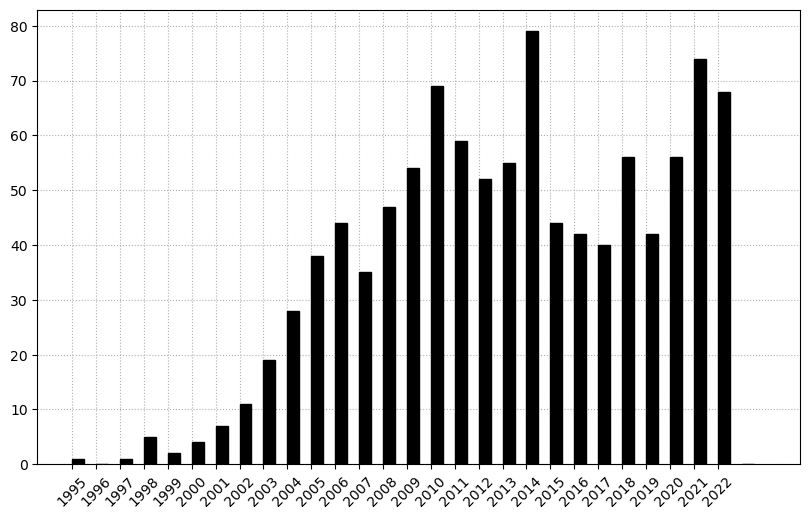

In [25]:
# Publication years – make a new column 

path = '/Users/owen/Documents/SSG Prism pres/'

import re

def add_year_col(df):
    expr = r".+([0-9]{4})[a-z]?"
    df['year'] = [int(re.match(expr,e).groups()[0]) for e in list(df.index)]
    return df

newdat = add_year_col(newdat)
olddat = add_year_col(olddat)

all_years_df = pd.concat([newdat[newdat.year < 2023].year, olddat.year])
cm = 1/2.54
figsize = (25*cm, 15*cm)
f, ax = plt.subplots(1,1, figsize=figsize)
all_years_df.hist(bins=range(1995,2025), align='mid', width=0.5, zorder=3,ax=ax)
print(ax.containers)

for bar in ax.containers[0]:
    print(bar)
    plt.setp(bar, color='black')

plt.grid(which='both',linestyle=':', zorder=0)
plt.xticks(range(1995,2023),rotation=45)
# plt.savefig(path + 'pubyears.png')


<Axes: xlabel='year', ylabel='Publications'>

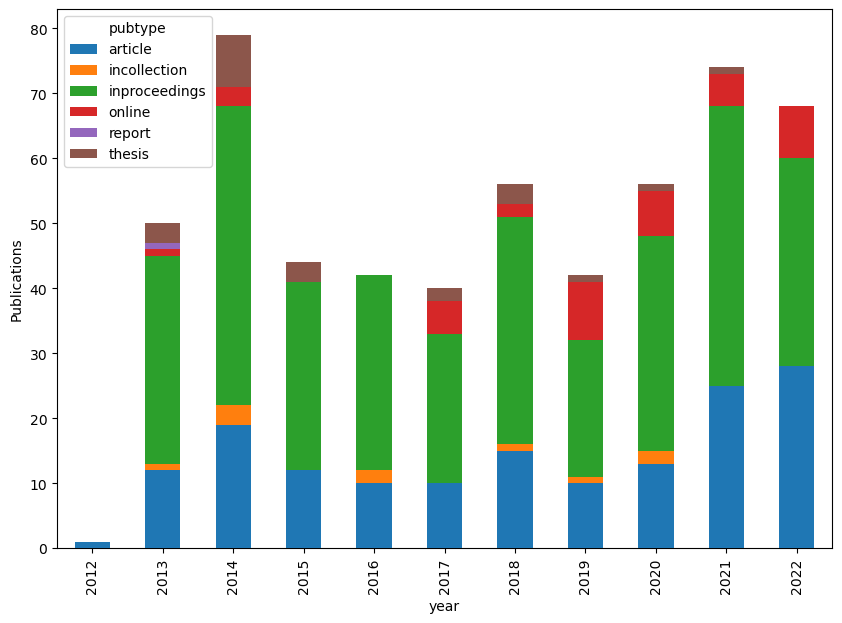

In [26]:

newdat['pubtype'] = [library.entries_dict[i].entry_type for i in newdat.index]

pub_piv = newdat[(newdat.year >= 2012) & (newdat.year <= 2022)].groupby('year')['pubtype'].value_counts().unstack()

fig,ax = plt.subplots(figsize=(10,7))
pub_piv.plot.bar(stacked=True,ylabel='Publications',ax = ax,zorder=3)



# Venues

In [22]:
# Basic counts by type 
types = [e.entry_type for e in library.entries]
entry_type_hist = Counter(types)
pprint.pprint(entry_type_hist)

Counter({'inproceedings': 331,
         'article': 156,
         'online': 40,
         'thesis': 23,
         'incollection': 10,
         'report': 1})


In [38]:
# Utility fns for drilling into bib data. 

def debrace(s): 
    '''
    Remove braces from bibtex keys 
    '''
    debrace_re = re.compile(r'[\{\}]')
    return debrace_re.sub(lambda x:'',s)

def conference(d): 
    '''
    Find a conference in either eventtitle or booktitle fields for inproceedings type 
    '''
    return debrace(list(filter(partial(is_not, None), [d.get(f) for f in ['eventtitle', 'booktitle']]))[0].value)


In [ ]:
# Let's see if we can make a reasonable list of unique publication venues

def venues(library):
    lookup = {
        'article':['journaltitle'], 
        'inproceedings': ['booktitle','eventtitle']
    }
    for e in library.entries: 
        # if e.entry_type in lookup.keys:
        ven_key = lookup.get(e.entry_type)
        if ven_key: 
            if len(ven_key) == 1:
                # ven = getattr(e,ven_key)
                try: 
                    ven = e.fields_dict[ven_key[0]].value
                except KeyError:
                    ven = ""
            else: 
                
                ven = [e.fields_dict.get(vki,"") for vki in ven_key]
                # ven = [e.value for e in ven if e is not None else ""]
                ven =list(map(lambda x: x.value if x else "", ven))
                
                ven = sorted(ven, key=len)[0]
            yield ven
        continue


unique_venues = set([v for v in venues(library)])

# [e for e in library.entries]

# venues = 
#     [library.entries_dict[i] for i in newdat.index]





In [40]:
# Bib data for conferencs and articles 
conf_papers = [e for e in library.entries if e.entry_type == 'inproceedings']
journal_articles  = [e for e in library.entries if e.entry_type == 'article']

In [45]:
# Take conference names and strip out years and 'nth so and so' conference to try and get unique 'venues' 
conferences = [conference(p) for p in conf_papers]
guff_re = re.compile(r'\s?(\d?\d(rd|st|nd|th))|\d{4}|\(.+\)\s?')
def raw_conf(s): 
    return guff_re.sub(lambda x:'', s).strip()

raw_conferences = [raw_conf(c) for c in conferences]

conference_counts = Counter(raw_conferences)
# TODO: check this over 
print(f'{len(conference_counts)} distinct conferences')
pprint.pprint(conference_counts)


233 distinct conferences
Counter({'Proceedings of the International Society for Music Information Retrieval Conference': 37,
         'IEEE International Conference on Acoustics, Speech and Signal Processing': 8,
         'International Joint Conference on Neural Networks': 7,
         'Interspeech': 5,
         'European Signal Processing Conference': 5,
         'Anais Do XVIII Simpósio Brasileiro de Computação Musical': 4,
         'Asia-Pacific Signal and Information Processing Association Annual Summit and Conference': 4,
         'International Conference on Computer Communication and Informatics': 4,
         'IEEE International Conference on Systems, Man, and Cybernetics': 3,
         'Proceedings of the International Conference on Music Information Retrieval': 3,
         'IEEE International Symposium on Multimedia': 3,
         'IEEE International Conference on Machine Learning and Applications': 2,
         'Innovations in Intelligent Systems and Applications Conference': 2,

In [46]:

conf_df = pd.DataFrame.from_dict(conference_counts, orient='index')
print(conf_df.value_counts()) 

1     196
2      26
3       3
4       3
5       2
7       1
8       1
37      1
Name: count, dtype: int64


In [53]:

journals = [j.fields_dict.get('journaltitle').value for j in journal_articles]
journals_count = Counter(journals)
pprint.pprint(journals_count)


Counter({'IEEE Access': 7,
         'Journal of Intelligent Information Systems': 4,
         'Applied Soft Computing': 4,
         'Expert Systems with Applications': 4,
         'IEEE Transactions on Multimedia': 4,
         'International Journal of Computer Applications': 4,
         'Multimedia Tools and Applications': 3,
         'Mathematics': 3,
         'Journal of New Music Research': 3,
         'IEEE Signal Processing Letters': 3,
         'EURASIP Journal on Audio, Speech, and Music Processing': 3,
         'Transactions of the International Society for Music Information Retrieval': 3,
         'IEEE/ACM Transactions on Audio, Speech, and Language Processing': 3,
         'Neural Computing and Applications': 2,
         'Archives of Acoustics': 2,
         'Electronics': 2,
         'International Research Journal of Engineering and Technology': 2,
         'Computational Intelligence and Neuroscience': 2,
         'Journal of Creative Music Systems': 2,
         'Jurnal E

In [55]:

journal_df = pd.DataFrame.from_dict(journals_count, orient='index')
print(journal_df.value_counts()) 

1    78
2    15
3     7
4     5
7     1
Name: count, dtype: int64


In [56]:
# util fns for checking over content of bib fields

def check_fields(dict, fields,search):   
    if not isinstance(fields, list):
        fields = [fields]    
    reg = re.compile(search,flags=re.IGNORECASE)
    # f = dict.get(field)
    def debrace(s): 
        debrace_re = re.compile(r'[\{\}]')
        return debrace_re.sub(lambda x:'',s)
    matches = [
        reg.search(debrace(v.value)) is not None for f in fields for v in [dict.get(f)] if v is not None 
    ]
    return len(matches) > 0 and reduce(or_, matches,False)

def check_terms(dict, fields, searches): 
    if not isinstance(searches, list):
        searches = [searches]
    return reduce(or_,[check_fields(dict, fields, s) for s in searches],False)


In [59]:
# Count  IEEE journal and conference papers 
ieee_journal = [j.key for j in journal_articles if  check_terms(j.fields_dict,'journaltitle','ieee')]
ieee_conf = [p.key for p in conf_papers if check_terms(p.fields_dict,['eventtitle', 'booktitle', 'url'],'ieee')]

print(len(ieee_journal),len(ieee_conf))


21 70
3 42


In [ ]:

# Count ISMIR 
ismir_journal = [j.key for j in journal_articles if  check_terms(j.fields_dict,'journaltitle',['ISMIR','international society for music information'])]
ismir_conf = [p.key for p in conf_papers if check_terms(p.fields_dict,['eventtitle', 'booktitle'],['ISMIR','international society for music information'])]
print(len(ismir_journal),len(ismir_conf))


# Engagement with Critical MIR

Some validation first. Make sure we can get critical citations from grepping PDFs to line up with what's in the spreadsheet:

In [31]:
# json file generated by PDF scraping script 
with open('data/critical_mir_citations.json', 'r') as f: 
    crit_cites = json.load(f)


In [32]:
# pdf scraping is fragile w/r/t things like line breaks and hyphens. It misses these
manual_critkeys = {
    "Pampalk2005b": ['poria2013','panagakis2014','prockup2015','deleon2014','kostrzewa2018','vatolkin2015a','seo2014','chen2016','eppler2014'], 
    'Flexer2007':['salazar2022','piccoli2013','costa2017','costa2013a','nanni2017','nanni2014'],
    "Flexer2006b": ['hartmann2013'], 
    "Flexer2009":['bogdanov2019'],
    "Flexer2010": ['panagakis2014','flexer2016','vatolkin2015a'], 
    'Kereliuk2015a': ['favory2020','park2018','jeong2016','lee2017','medhat2017b','favory2020a'], 
    "Sturm2012b": ['lu2016','flexer2016','lu2016a','mujtaba2019','rompre2017','schreiber2015','sigtia2014'],
    "Sturm2012c": ['koerich2013'],
    "Sturm2012e": ['kereliuk2015','correa2016','tavares2018','costa2017','nanni2017'],
    "Sturm2013c": ['silva2020'],
    "Sturm2013g": ['Porter2016','kereliuk2015','jao2015','mckay2018'],
    "Sturm2013h": ['kereliuk2015','lu2016','prockup2015','jeong2016','sheikhfathollahi2021','mujtaba2019','silva2021a'], 
    "Sturm2015a": ['jeong2016']
}

In [33]:
# check that, with the manual set above, citations agree between spreadsheet and scraping
critkeys = []

for k,v in crit_cites.items(): 
    critkeys.extend(v)    
    man_cites = manual_critkeys.get(k) 
    if man_cites: 
        critkeys.extend(man_cites)

critkeys = set(map(lambda x: x.lower(),critkeys))
dat_critkeys = set(map(lambda x: x.lower(),newdat[newdat.curiosity['Cites Critical MIR'] > 0].index))

print('In JSON not in spreadsheet:')
print(critkeys - dat_critkeys)
print('In spreadsheet not in JSON:')
print(dat_critkeys - critkeys)


In JSON not in spreadsheet:
set()
In spreadsheet not in JSON:
set()


In [35]:
# Counts of cites / engagement
newdat.curiosity.sum(axis=0)

Cites Critical MIR      162.0
Engages Critical MIR     76.0
Cites Genre-Theory       36.0
Engages Genre-Theory     11.0
dtype: float64

In [ ]:
# papers that use gtzan and cite critical work 
# (could be more specific and look only for work citing Sturm2012b and Sturm2013)?



## Number of crit citations

In [ ]:
print(len(dat_critkeys))